# Breast ultrasound AI — end to end

Research notebook for this repository's breast ultrasound images. It is the only project notebook.

It can run five components, one at a time:

- YOLO26n tumor detection
- U-Net tumor segmentation
- ResNet50 benign/malignant classification on a masked region
- BI-RADS retrieval with a local embedding model and a FAISS index
- A small local language model that may draft report prose

The language model does not assign a diagnosis or a BI-RADS category. A physician has to approve findings before an approved report is exported. Set `TRAIN_MODE = False` to run inference from the saved checkpoints. Restart the kernel and run all cells from the repository root.


## Configuration

Change the paths and switches here. Leave training off unless you intend to fine-tune. `EVAL_LIMIT` is the number of test-split images used for the metrics printed below. Set it to `None` to use every test image. The demo image is separate from that sample.


In [1]:
from pathlib import Path
import sys

TRAIN_MODE = False
EVAL_LIMIT = 12
REBUILD_RAG_INDEX = False
PHYSICIAN_APPROVE_EXPORT = False
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45
MATCH_IOU = 0.5
LLM_MODEL_ID = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
EMBED_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
IMAGE_PATH = None  # set to a PNG path to replace the default demo image

ROOT = Path.cwd().resolve()
if not (ROOT / "config.yaml").exists():
    for parent in [ROOT, *ROOT.parents]:
        if (parent / "config.yaml").exists():
            ROOT = parent
            break
if not (ROOT / "config.yaml").exists():
    raise FileNotFoundError("Run this notebook from the repository that contains config.yaml.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("root", ROOT)
print("train mode", TRAIN_MODE, "eval limit", EVAL_LIMIT, "rebuild rag", REBUILD_RAG_INDEX)


root /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection
train mode False eval limit 12 rebuild rag False


## Hardware and environment

The target machine is a MacBook Air M4 with 24 GB unified memory. MedGemma 27B is refused. MedGemma 1.5 4B is not downloaded: its published shards are 4.96 GB and 3.64 GB. The local generator is TinyLlama 1.1B, which is already stored on this machine. It is a general chat model, not a medical foundation model.


In [2]:
from utils.config import load_config
from utils.hardware import disk_bytes, hardware_snapshot
from utils.seed import get_device, set_seed
from notebooks.cascade_workflow import medgemma_decision, rss_gib

config = load_config(ROOT / "config.yaml")
set_seed(config["seed"], deterministic=True)
DEVICE = get_device(config.get("device"))
SNAP = hardware_snapshot(ROOT)
print(f"torch {SNAP['torch']}  cuda {SNAP['cuda']}  mps {SNAP['mps']}  device {DEVICE}")
print(f"RAM {SNAP['ram_bytes']/1024**3:.2f} GiB  RSS {rss_gib():.2f} GiB  free disk {SNAP['disk_free_bytes']/1024**3:.1f} GiB")
if SNAP["disk_free_bytes"] < 2 * 1024**3:
    raise RuntimeError("Less than 2 GB free disk.")
MEDGEMMA = medgemma_decision()
for item in MEDGEMMA["decisions"]:
    print(item["model_id"], "allowed" if item["allowed"] else "refused")
    if not item["allowed"]:
        print(item["reason"])
print(MEDGEMMA["local_generator_note"])
OUTPUT_DIR = ROOT / "results" / "notebook_end_to_end"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY = {}
PEAK_RSS = SNAP["rss_bytes"]

def remember_rss():
    global PEAK_RSS
    from utils.hardware import current_rss_bytes
    PEAK_RSS = max(PEAK_RSS, current_rss_bytes())
    return PEAK_RSS


torch 2.12.1  cuda False  mps True  device mps
RAM 24.00 GiB  RSS 0.38 GiB  free disk 204.3 GiB
google/medgemma-27b-text-it refused
Refusing to download or load google/medgemma-27b-text-it. A 27B checkpoint does not fit a 24 GB MacBook Air and is not used by this project.
google/medgemma-1.5-4b-it refused
Refusing to download or load google/medgemma-1.5-4b-it. Published weights are 4.96 GB + 3.64 GB (8.60 GB), above the 8 GB optional-checkpoint limit. The ultrasound classifier does not use this model.
A general 1.1B chat model already stored on this machine. It is not a medical foundation model and it does not assign a diagnosis.


## Dataset inspection

The images are ultrasound PNGs. The folder name is the only classification label. There is no patient identifier, so a patient-level split cannot be created. Masks supply detection and segmentation annotations. BI-RADS descriptors are not in the dataset.


In [3]:
import json
from collections import Counter
from dataset.manifest import build_manifest
from notebooks.cascade_workflow import read_split_rows

paths = config["paths"]
records = build_manifest(
    ROOT / paths["raw_benign"], ROOT / paths["raw_benign_mask"],
    ROOT / paths["raw_malignant"], ROOT / paths["raw_malignant_mask"],
)
print("images", len(records), dict(Counter(record.label for record in records)))
print("masks", sum(len(record.mask_paths) for record in records))
print("images without a mask", sum(len(record.mask_paths) == 0 for record in records))
print("patient identifiers: none")
test_rows = read_split_rows(ROOT, "test")
print("saved test split", len(test_rows))

def sample_rows(rows, limit):
    if limit is None or limit >= len(rows):
        return rows
    half = max(1, limit // 2)
    benign = [row for row in rows if row["label"] == "benign"][:half]
    malignant = [row for row in rows if row["label"] == "malignant"][: limit - len(benign)]
    return benign + malignant

eval_rows = sample_rows(test_rows, EVAL_LIMIT)
print("evaluation images", len(eval_rows), dict(Counter(row["label"] for row in eval_rows)))
print("This sample is not a patient-level test. Near-duplicate frames can still cross the older saved split.")
SUMMARY["dataset"] = {"status": "executed", "images": len(records), "eval_images": len(eval_rows)}


images 647 {'benign': 437, 'malignant': 210}
masks 665
images without a mask 0
patient identifiers: none
saved test split 97
evaluation images 12 {'benign': 6, 'malignant': 6}
This sample is not a patient-level test. Near-duplicate frames can still cross the older saved split.


## Checkpoints and the demo image

Inference uses the saved YOLO26n, U-Net, and ResNet50 checkpoints. Training is a separate switch and does not run during an ordinary Restart Kernel → Run All.


In [4]:
from notebooks.cascade_workflow import checkpoint_status

CHECKPOINTS = {
    "yolo": ROOT / config["inference"]["yolo_weights"],
    "unet": ROOT / config["inference"]["unet_weights"],
    "resnet": ROOT / config["inference"]["resnet_weights"],
}
for name, path in CHECKPOINTS.items():
    status = checkpoint_status(path)
    print(name, "available" if status["available"] else "MISSING", status["path"], status["bytes"])
    SUMMARY[f"checkpoint_{name}"] = status

demo_path = Path(IMAGE_PATH) if IMAGE_PATH else ROOT / "dataset/BUSI_Jpeg/benign/benign (100).png"
if not demo_path.is_absolute():
    demo_path = ROOT / demo_path
if not demo_path.exists():
    raise FileNotFoundError(f"Demo image not found: {demo_path}. Set IMAGE_PATH to an ultrasound PNG.")
print("demo image", demo_path)
demo_image = None
demo_mask = None
truth_boxes = []
quality = {"status": "unavailable", "height": 0, "width": 0, "comments": ["Image was not loaded."]}
roi = None
roi_mask = None
pred_mask = None
roi_size = tuple(config["preprocessing"]["roi_size"])


yolo available /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection/checkpoints/yolo/busi_tumor/weights/best.pt 5384133
unet available /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection/checkpoints/unet/best_unet.pth 97916747
resnet available /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection/checkpoints/resnet/best_resnet.pth 94363799
demo image /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection/dataset/BUSI_Jpeg/benign/benign (100).png


## A. YOLO26n — tumor detection

The cell loads only the detector, draws the top box, and compares it with the box of the ground-truth mask. It then scores the evaluation sample and unloads the detector. Set `TRAIN_MODE = True` before Run All only when you want a real fine-tune.


image quality {'status': 'pass', 'height': 473, 'width': 323, 'comments': []}
detections 2 ground-truth boxes 1


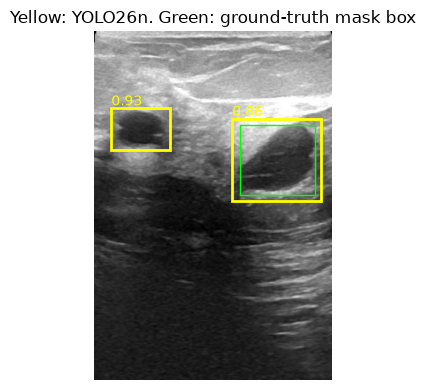

{'images': 12, 'true_positive': 11, 'false_positive': 1, 'false_negative': 1, 'precision': 0.9166666666666666, 'recall': 0.9166666666666666}
false positive ids ['benign (194)']
false negative ids ['benign (194)']
peak RSS GiB 0.975341796875


In [5]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from notebooks.cascade_workflow import (
    detect_image, evaluate_detection, ground_truth_boxes, load_yolo, release_memory, union_mask,
)
from preprocessing.normalization import load_image_rgb

YOLO_RESULT = {"status": "unavailable"}
try:
    if not SUMMARY["checkpoint_yolo"]["available"]:
        raise FileNotFoundError(CHECKPOINTS["yolo"])
    yolo_model = load_yolo(CHECKPOINTS["yolo"])
    demo_image = load_image_rgb(demo_path)
    from notebooks.cascade_workflow import check_image_quality
    quality = check_image_quality(demo_image)
    print("image quality", quality)
    detections = detect_image(yolo_model, demo_image, config["yolo"]["imgsz"], CONF_THRESHOLD, IOU_THRESHOLD, str(DEVICE))
    mask_candidates = []
    for split_name in ("train", "val", "test"):
        mask_candidates.extend(row for row in read_split_rows(ROOT, split_name) if Path(row["image_path"]) == demo_path)
    if demo_path.name == "benign (100).png":
        mask_paths = [str(ROOT / "dataset/BUSI_Jpeg/benign_mask/benign (100)_mask.png")]
    elif mask_candidates:
        mask_paths = mask_candidates[0]["mask_paths"]
    else:
        mask_paths = []
    demo_mask = union_mask(mask_paths, demo_image.shape[:2]) if mask_paths else np.zeros(demo_image.shape[:2], np.uint8)
    truth_boxes = ground_truth_boxes(demo_mask, min_area_px=20)
    print("detections", len(detections), "ground-truth boxes", len(truth_boxes))
    fig, axis = plt.subplots(figsize=(5, 4))
    axis.imshow(demo_image)
    for box, score in detections:
        x0, y0, x1, y1 = box
        axis.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="yellow", linewidth=2))
        axis.text(x0, max(0, y0 - 4), f"{score:.2f}", color="yellow")
    for box in truth_boxes:
        x0, y0, x1, y1 = box
        axis.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="lime", linewidth=1))
    axis.set_title("Yellow: YOLO26n. Green: ground-truth mask box")
    axis.axis("off")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "yolo_demo.png", dpi=120)
    plt.show()
    detection_eval = evaluate_detection(
        yolo_model, eval_rows, CONF_THRESHOLD, IOU_THRESHOLD, config["yolo"]["imgsz"], str(DEVICE), MATCH_IOU
    )
    print({key: detection_eval[key] for key in ("images", "true_positive", "false_positive", "false_negative", "precision", "recall")})
    print("false positive ids", detection_eval["false_positive_ids"])
    print("false negative ids", detection_eval["false_negative_ids"])
    (OUTPUT_DIR / "yolo_eval.json").write_text(json.dumps(detection_eval, indent=2))
    YOLO_RESULT = {"status": "executed", "detections": [(list(box), score) for box, score in detections], "eval": detection_eval}
    del yolo_model
    release_memory()
except Exception as exc:
    YOLO_RESULT = {"status": "unavailable", "error": str(exc)}
    print("YOLO26 unavailable:", exc)
SUMMARY["yolo"] = {"status": YOLO_RESULT["status"]}
remember_rss()
print("peak RSS GiB", remember_rss() / 1024**3)


In [6]:
if not TRAIN_MODE:
    print("YOLO training skipped. TRAIN_MODE is False, so the saved checkpoint is used.")
    SUMMARY["yolo_train"] = {"status": "skipped", "reason": "TRAIN_MODE is False"}
else:
    data_yaml = ROOT / paths["yolo_dataset_dir"] / "data.yaml"
    if not data_yaml.exists():
        print("YOLO training unavailable. Dataset yaml is missing:", data_yaml)
        SUMMARY["yolo_train"] = {"status": "unavailable", "reason": "data.yaml missing"}
    else:
        from yolo.train import train_yolo
        train_yolo(config, data_yaml, resume=False)
        SUMMARY["yolo_train"] = {"status": "executed"}


YOLO training skipped. TRAIN_MODE is False, so the saved checkpoint is used.


## B. U-Net — tumor segmentation

Segmentation uses the ground-truth lesion region for the metric, so a missed detection is not counted as a segmentation error. The figure shows the demo image's region, the predicted mask, and the overlay.


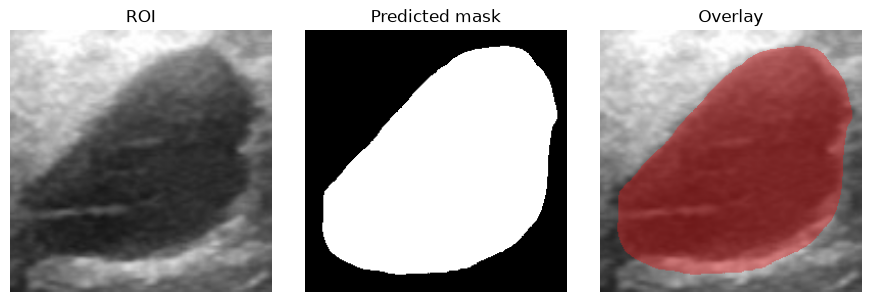

demo segmentation {'dice': 0.9731392536040757, 'iou': 0.9476837604511351, 'precision': 0.964227326886408, 'recall': 0.982217455120294, 'specificity': 0.9571210309553703}
sample mean {'dice': 0.9205711365873439, 'iou': 0.8555900549432452, 'precision': 0.9039087687838744, 'recall': 0.9425163072532067, 'specificity': 0.899818606367225} images 12
U-Net training skipped. TRAIN_MODE is False.


In [7]:
from notebooks.cascade_workflow import evaluate_segmentation, load_unet, release_memory, segment_roi
from preprocessing.roi_utils import crop_roi_pair

UNET_RESULT = {"status": "unavailable"}
try:
    if not SUMMARY["checkpoint_unet"]["available"]:
        raise FileNotFoundError(CHECKPOINTS["unet"])
    unet_model = load_unet(config, CHECKPOINTS["unet"], DEVICE)
    roi_size = tuple(config["preprocessing"]["roi_size"])
    if demo_mask.sum() == 0 or not truth_boxes:
        raise RuntimeError("The demo image has no ground-truth mask, so the ROI for segmentation is unavailable.")
    x0 = min(box[0] for box in truth_boxes)
    y0 = min(box[1] for box in truth_boxes)
    x1 = max(box[2] for box in truth_boxes)
    y1 = max(box[3] for box in truth_boxes)
    roi, roi_mask, _ = crop_roi_pair(demo_image, demo_mask, (x0, y0, x1, y1), pad_ratio=0.08, target_size=roi_size)
    pred_mask = segment_roi(unet_model, roi, DEVICE)
    overlay = roi.copy()
    overlay[pred_mask > 0] = (0.55 * overlay[pred_mask > 0] + np.array([220, 30, 30]) * 0.45).astype(overlay.dtype)
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))
    axes[0].imshow(roi); axes[0].set_title("ROI"); axes[0].axis("off")
    axes[1].imshow(pred_mask, cmap="gray"); axes[1].set_title("Predicted mask"); axes[1].axis("off")
    axes[2].imshow(overlay); axes[2].set_title("Overlay"); axes[2].axis("off")
    fig.tight_layout(); fig.savefig(FIGURE_DIR / "unet_demo.png", dpi=120); plt.show()
    from evaluation.metrics import segmentation_metrics
    print("demo segmentation", segmentation_metrics(pred_mask, roi_mask))
    segmentation_eval = evaluate_segmentation(unet_model, eval_rows, DEVICE, roi_size)
    print("sample mean", segmentation_eval.get("mean"), "images", segmentation_eval.get("images"))
    (OUTPUT_DIR / "unet_eval.json").write_text(json.dumps(segmentation_eval, indent=2))
    np.save(OUTPUT_DIR / "demo_pred_mask.npy", pred_mask)
    UNET_RESULT = {"status": "executed", "demo": segmentation_metrics(pred_mask, roi_mask), "eval": segmentation_eval}
    del unet_model
    release_memory()
except Exception as exc:
    UNET_RESULT = {"status": "unavailable", "error": str(exc)}
    print("U-Net unavailable:", exc)
SUMMARY["unet"] = {"status": UNET_RESULT["status"]}
remember_rss()

if not TRAIN_MODE:
    print("U-Net training skipped. TRAIN_MODE is False.")
    SUMMARY["unet_train"] = {"status": "skipped", "reason": "TRAIN_MODE is False"}
else:
    from unet.train import train_unet
    train_unet(config, resume=False)
    SUMMARY["unet_train"] = {"status": "executed"}


## C. ResNet50 — benign or malignant

The classifier sees the ground-truth masked region, which is the input it was trained on. The folder label is the reference. A probability is not a BI-RADS assessment.


demo folder label: benign for benign (100); predicted {'predicted_class': 'benign', 'confidence': 0.8730345964431763, 'probabilities': {'benign': 0.8730345964431763, 'malignant': 0.12696535885334015}}
{'images': 12, 'sensitivity_malignant': 0.8333333333333334, 'specificity_benign': 1.0, 'precision_malignant': 1.0, 'f1_malignant': 0.9090909090909091, 'roc_auc': 0.9722222222222223, 'pr_auc': 0.976190476190476}
confusion rows benign/malignant [[6, 0], [1, 5]]


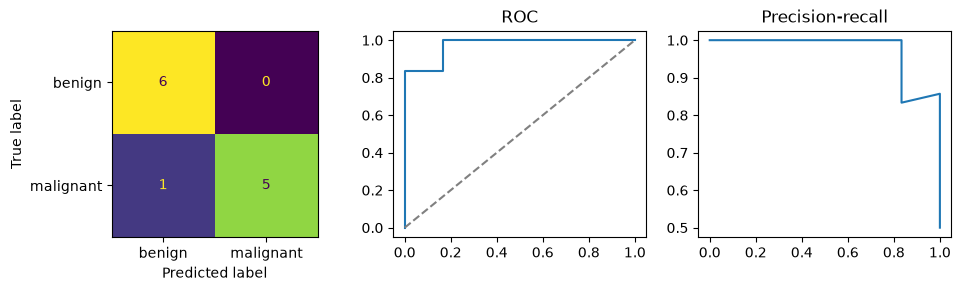

ResNet50 training skipped. TRAIN_MODE is False.


In [8]:
from notebooks.cascade_workflow import classify_roi, evaluate_classification, load_resnet, release_memory
from preprocessing.roi_utils import apply_mask
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

RESNET_RESULT = {"status": "unavailable"}
try:
    if not SUMMARY["checkpoint_resnet"]["available"]:
        raise FileNotFoundError(CHECKPOINTS["resnet"])
    resnet_model = load_resnet(config, CHECKPOINTS["resnet"], DEVICE)
    masked = apply_mask(roi, pred_mask if UNET_RESULT["status"] == "executed" else roi_mask)
    # Metrics below use the ground-truth mask. The probabilities printed for the demo use that same ground-truth mask.
    demo_class = classify_roi(resnet_model, apply_mask(roi, roi_mask), DEVICE)
    print("demo folder label: benign for benign (100); predicted", demo_class)
    classification_eval = evaluate_classification(resnet_model, eval_rows, DEVICE, roi_size)
    print({key: classification_eval[key] for key in ("images", "sensitivity_malignant", "specificity_benign", "precision_malignant", "f1_malignant", "roc_auc", "pr_auc")})
    print("confusion rows benign/malignant", classification_eval["confusion_matrix"])
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    ConfusionMatrixDisplay(np.array(classification_eval["confusion_matrix"]), display_labels=["benign", "malignant"]).plot(ax=axes[0], colorbar=False)
    if classification_eval["roc_curve"]:
        axes[1].plot(classification_eval["roc_curve"]["fpr"], classification_eval["roc_curve"]["tpr"])
        axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
        axes[1].set_title("ROC")
        axes[2].plot(classification_eval["pr_curve"]["recall"], classification_eval["pr_curve"]["precision"])
        axes[2].set_title("Precision-recall")
    fig.tight_layout(); fig.savefig(FIGURE_DIR / "resnet_curves.png", dpi=120); plt.show()
    public_eval = {key: value for key, value in classification_eval.items() if key not in {"roc_curve", "pr_curve"}}
    (OUTPUT_DIR / "resnet_eval.json").write_text(json.dumps(public_eval, indent=2))
    RESNET_RESULT = {"status": "executed", "demo": demo_class, "eval": public_eval}
    del resnet_model
    release_memory()
except Exception as exc:
    RESNET_RESULT = {"status": "unavailable", "error": str(exc)}
    print("ResNet50 unavailable:", exc)
SUMMARY["resnet"] = {"status": RESNET_RESULT["status"]}
remember_rss()

if not TRAIN_MODE:
    print("ResNet50 training skipped. TRAIN_MODE is False.")
    SUMMARY["resnet_train"] = {"status": "skipped", "reason": "TRAIN_MODE is False"}
else:
    from resnet.train import train_resnet
    train_resnet(config, resume=False)
    SUMMARY["resnet_train"] = {"status": "executed"}


## D. RAG — BI-RADS retrieval

The two supplied PDFs are split into chunks that keep the source id and the PDF page. A local MiniLM embedding model builds a FAISS inner-product index. An existing index is loaded unless `REBUILD_RAG_INDEX` is true. Retrieval quality is the fraction of prepared questions whose top 5 chunks contain an expected phrase from the expected document.


In [9]:
from bus_research.rag_eval import QUESTIONS
from notebooks.cascade_workflow import build_or_load_faiss, retrieval_recall, search_faiss

RAG_RESULT = {"status": "unavailable"}
try:
    rag_sources = [source for source in config["research"]["rag"]["sources"] if source["kind"] == "pdf"]
    if not rag_sources:
        raise RuntimeError("No PDF BI-RADS sources are configured.")
    rag_dir = OUTPUT_DIR / "faiss"
    rag_build = build_or_load_faiss(
        ROOT, rag_sources, EMBED_MODEL_ID, rag_dir,
        chunk_words=config["research"]["rag"]["chunk_words"],
        overlap_words=config["research"]["rag"]["chunk_overlap_words"],
        rebuild=REBUILD_RAG_INDEX,
    )
    print("index", rag_build["status"], "chunks", rag_build["n_chunks"])
    question = "What margin terms does the ultrasound lexicon use for a mass that is not circumscribed?"
    hits = search_faiss(rag_dir, question, k=5)
    for hit in hits:
        print(f"{hit['source_id']} page {hit['page']} score {hit['score']} | {hit['section']}")
        print(hit["text"][:280])
        print("---")
    recall = retrieval_recall(rag_dir, QUESTIONS, k=5)
    print("recall@5", round(recall["recall_at_5"], 3), "on", recall["questions"], "questions")
    (OUTPUT_DIR / "rag_hits.json").write_text(json.dumps({"question": question, "hits": hits, "recall": recall}, indent=2))
    RAG_RESULT = {"status": "executed", "hits": hits, "recall": recall, "index_dir": str(rag_dir)}
except Exception as exc:
    RAG_RESULT = {"status": "unavailable", "error": str(exc)}
    print("RAG unavailable:", exc)
SUMMARY["rag"] = {"status": RAG_RESULT["status"], "recall_at_5": None if RAG_RESULT["status"] != "executed" else RAG_RESULT["recall"]["recall_at_5"]}
remember_rss()


index loaded chunks 49


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

lee-2017-us-birads page 6 score 0.6592 | printed p. 76; mass orientation
Jiyon Lee 76 Ultrasonography 36(1), January 2017 e-ultrasonography.org fall neatly into one of these strict definitions. For example, benign- appearing masses with more than three lobulations are common (Fig. 3). The radiologist should use judgment and communicate the details of 
---
lee-2017-us-birads page 3 score 0.6275 | printed p. 73; tissue composition
(masses, calcifications, associated features, and special cases), and lexicon classification. US: Tissue Composition Now recommended is a mention of the dominant tissue composition on the screening US (Fig. 1). This should correlate with mammography, if performed. “Homogeneous ba
---
lee-2017-us-birads page 5 score 0.5899 | printed p. 75; mass margin
Practical summary of updated US BI-RADS e-ultrasonography.org Ultrasonography 36(1), January 2017 75 up to 2 -3 gentle lobulations), round (i.e., spherical, ball shaped, globular), and irregular (neither round nor 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

recall@5 0.6 on 10 questions


1086881792

## E. Local LLM — structured report draft

MedGemma is not loaded. TinyLlama drafts JSON from the model outputs and the retrieved passages. If it invents a BI-RADS category or a descriptor, that prose is discarded. If the model cannot load, the report states that LLM generation was not executed. The structured fields still have to match the Pydantic schema.


In [10]:
from bus_research.geometry import geometry_from_mask
from notebooks.cascade_workflow import assemble_report, generate_with_local_llm, parse_llm_json

passages = RAG_RESULT.get("hits", [])[:3] if RAG_RESULT["status"] == "executed" else []
facts = {
    "image": demo_path.name,
    "quality": quality["status"],
    "detection": None if YOLO_RESULT["status"] != "executed" else YOLO_RESULT["detections"][:1],
    "classification": None if RESNET_RESULT["status"] != "executed" else RESNET_RESULT["demo"],
    "descriptors": "not available",
    "physician_approved": False,
}
passage_text = [
    {"source_id": hit["source_id"], "page": hit["page"], "citation": hit["citation"], "text": hit["text"][:500]}
    for hit in passages
]
messages = [
    {"role": "system", "content": "You draft a research note. You are not a physician. Never assign a BI-RADS number. Never invent shape, margin, echo pattern, or orientation. Reply with one JSON object only."},
    {"role": "user", "content": "Facts:\n" + json.dumps(facts) + "\nPassages:\n" + json.dumps(passage_text) + "\nKeys: findings, impression, limitations, citations. Say that the model outputs are unverified."},
]
LLM_RESULT = {"status": "unavailable", "executed": False}
llm_payload = None
try:
    generated = generate_with_local_llm(LLM_MODEL_ID, messages, max_new_tokens=280)
    (OUTPUT_DIR / "llm_raw.txt").write_text(generated["text"])
    llm_payload = parse_llm_json(generated["text"])
    LLM_RESULT = {"status": "executed", "executed": True, "model_id": generated["model_id"], "parameter_count": generated["parameter_count"], "rss_loaded_gib": generated["rss_loaded_bytes"] / 1024**3, "json_parsed": llm_payload is not None}
    print("LLM parameters", LLM_RESULT["parameter_count"], "RSS GiB", round(LLM_RESULT["rss_loaded_gib"], 2), "report JSON", llm_payload is not None)
    print((generated["text"] or "")[:800])
except Exception as exc:
    LLM_RESULT = {"status": "unavailable", "executed": False, "error": str(exc)}
    print("LLM was not executed:", exc)
SUMMARY["llm"] = {"status": LLM_RESULT["status"], "model_id": LLM_MODEL_ID if LLM_RESULT.get("executed") else None}
remember_rss()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=280) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


LLM parameters 1100048384 RSS GiB 0.29 report JSON False
Facts:
{"image": "benign (100).png", "quality": "pass", "detection": [[[23, 104, 102, 160], 0.9340729117393494]], "classification": {"predicted_class": "benign", "confidence": 0.8730345964431763, "probabilities": {"benign": 0.8730345964431763, "malignant": 0.12696535885334015}}, "descriptors": "not available", "physician_approved": false}
Passages:
[{"source_id": "lee-2017-us-birads", "page": 6, "citation": "Lee J. Practical and illustrated summary of updated BI-RADS for ultrasonography. Ultrasonography. 2017;36(1):71-81. doi:10.14366/usg.16034", "text


1086881792

## End-to-end inference

The same demo image goes through quality check, detection, segmentation, classification, descriptor extraction, retrieval, and report validation. Descriptor extraction reports that no lexicon labels exist. Geometry from the mask is auxiliary and is not a BI-RADS orientation. Physician approval stays pending, so the approved export is not written.


In [11]:
from bus_research.review_workflow import ReviewWorkflow, WorkflowError

workflow = ReviewWorkflow(study_id=demo_path.stem)
geometry = geometry_from_mask(pred_mask if UNET_RESULT["status"] == "executed" else demo_mask)
detection_block = {
    "lesion_detected": bool(YOLO_RESULT.get("detections")),
    "bounding_box": YOLO_RESULT["detections"][0][0] if YOLO_RESULT.get("detections") else None,
    "confidence": YOLO_RESULT["detections"][0][1] if YOLO_RESULT.get("detections") else None,
}
segmentation_block = {
    "mask_reference": str(OUTPUT_DIR / "demo_pred_mask.npy") if (OUTPUT_DIR / "demo_pred_mask.npy").exists() else None,
}
classification_block = {
    "predicted_class": None if RESNET_RESULT["status"] != "executed" else RESNET_RESULT["demo"]["predicted_class"],
    "probability": None if RESNET_RESULT["status"] != "executed" else RESNET_RESULT["demo"]["confidence"],
}
print("auxiliary geometry orientation_assignment", geometry.get("orientation_assignment"))
print(geometry.get("note", "")[:240])
assembled = assemble_report(
    study_id=demo_path.stem,
    quality=quality,
    detection=detection_block,
    segmentation=segmentation_block,
    classification=classification_block,
    geometry=geometry,
    passages=passages,
    llm_payload=llm_payload,
    llm_executed=bool(LLM_RESULT.get("executed")),
    workflow_log=workflow.audit_log,
    physician_approved=False,
)
print("schema valid", assembled["schema_valid"], "llm text used", assembled["llm_text_used"])
print("unresolved", assembled["claim_flags"])
draft_path = OUTPUT_DIR / "draft_report.json"
draft_path.write_text(json.dumps(assembled["report"], indent=2))
print("draft", draft_path)
try:
    workflow.assert_ready("report")
    approved_allowed = True
except WorkflowError as exc:
    approved_allowed = False
    print("Approved export blocked:", exc)
if PHYSICIAN_APPROVE_EXPORT and approved_allowed:
    approved_path = OUTPUT_DIR / "approved_report.json"
    approved_path.write_text(draft_path.read_text())
    SUMMARY["approved_export"] = {"status": "executed", "path": str(approved_path)}
else:
    print("No approved report was exported. Set the review stages to approved only after a qualified person reviews the draft.")
    SUMMARY["approved_export"] = {"status": "withheld", "reason": "physician approval is pending"}
SUMMARY["end_to_end"] = {
    "status": "executed" if assembled["schema_valid"] else "unavailable",
    "llm_text_used": assembled["llm_text_used"],
    "schema_valid": assembled["schema_valid"],
}
remember_rss()


auxiliary geometry orientation_assignment None
Auxiliary mask geometry only. Not a BI-RADS shape, margin, orientation, or echo-pattern decision. A round lesion is not assigned an orientation.
schema valid True llm text used False
unresolved ['A detection is present in the report without physician approval.']
draft /Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection/results/notebook_end_to_end/draft_report.json
Approved export blocked: report is blocked: image_quality is pending, not approved
No approved report was exported. Set the review stages to approved only after a qualified person reviews the draft.


1086881792

## Execution summary

A stage marked `executed` ran in this kernel. `skipped` means training was left off on purpose. `unavailable` means a file, a model, or a dependency stopped that stage. Metrics above are the numbers just computed. They are not a clinical claim.


In [12]:
summary = {
    "notebook": "notebooks/Breast_Ultrasound_AI_End_to_End.ipynb",
    "device": str(DEVICE),
    "peak_rss_gib": remember_rss() / 1024**3,
    "stages": SUMMARY,
    "yolo": {key: YOLO_RESULT[key] for key in YOLO_RESULT if key != "eval"},
    "unet_status": UNET_RESULT["status"],
    "resnet_status": RESNET_RESULT["status"],
    "rag_status": RAG_RESULT["status"],
    "llm": LLM_RESULT,
    "medgemma": MEDGEMMA,
    "disclaimer": "Research classification and detection only. Not a clinical diagnosis and not a BI-RADS assessment.",
}
if YOLO_RESULT.get("eval"):
    summary["yolo_eval"] = {key: YOLO_RESULT["eval"][key] for key in ("images", "precision", "recall", "true_positive", "false_positive", "false_negative")}
if UNET_RESULT.get("eval"):
    summary["unet_eval_images"] = UNET_RESULT["eval"].get("images")
    summary["unet_mean"] = UNET_RESULT["eval"].get("mean")
if RESNET_RESULT.get("eval"):
    summary["resnet_eval"] = {key: RESNET_RESULT["eval"][key] for key in ("images", "sensitivity_malignant", "specificity_benign", "roc_auc", "pr_auc", "confusion_matrix")}
(OUTPUT_DIR / "execution_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps({key: summary[key] for key in ("device", "peak_rss_gib", "stages")}, indent=2))
print(summary["disclaimer"])
required = ["yolo", "unet", "resnet", "rag"]
failed = [name for name in required if SUMMARY.get(name, {}).get("status") != "executed"]
if failed:
    raise RuntimeError(f"Required stages did not execute: {failed}")


{
  "device": "mps",
  "peak_rss_gib": 1.012237548828125,
  "stages": {
    "dataset": {
      "status": "executed",
      "images": 647,
      "eval_images": 12
    },
    "checkpoint_yolo": {
      "available": true,
      "path": "/Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection/checkpoints/yolo/busi_tumor/weights/best.pt",
      "bytes": 5384133
    },
    "checkpoint_unet": {
      "available": true,
      "path": "/Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection/checkpoints/unet/best_unet.pth",
      "bytes": 97916747
    },
    "checkpoint_resnet": {
      "available": true,
      "path": "/Users/mulatyazewchekol/Documents/My_Projects/Healthcare_Projects/Breast_Cancer_Detection/checkpoints/resnet/best_resnet.pth",
      "bytes": 94363799
    },
    "yolo": {
      "status": "executed"
    },
    "yolo_train": {
      "status": "skipped",
      "reason": "TRAIN_MODE is False"
    },
    "unet": {
  